# Tugas Praktikum - Perbandingan Colab dan PyDroid3

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/tugas)

## Data hasil dan ruang lingkup

Laporan ini memakai output Google Colab dan PyDroid3 yang diberikan pengguna, beserta spesifikasi HP **Dimensity 8500 Ultra, RAM 16 GB**. Nilai disalin dari output konsol ke `hasil_colab.json` dan `hasil_android.json`; waktu tersedia sampai tiga angka desimal dan recall sampai empat angka desimal. Ini bukan unggahan JSON asli. Informasi yang tidak diberikan, seperti versi Python, model CPU Colab, jumlah thread, dan nama model HP, tidak diisi dengan perkiraan.

Kedua run memakai seed 42 pada kode, 10.000 vektor, 128 dimensi, k=10, StandardScaler, 10 tree Annoy, serta HNSW M=16, ef_construction=200, ef=200. Colab juga memakai FAISS IVF nlist=100 dan nprobe=10. **FAISS tetap dijalankan di Colab dan tidak dijalankan di PyDroid3** karena kendala instalasi pada HP pengguna.

Waktu mencakup **pembangunan indeks dan pencarian seluruh 10.000 baris terhadap database yang sama**, termasuk item itu sendiri. Tabel berikut membandingkan total workload tersebut, bukan latensi query murni.

Kode mandiri: [Colab dengan FAISS](benchmark_colab.py) dan [PyDroid3 tanpa FAISS](benchmark_pydroid3.py).

## Persiapan dan kode benchmark

Untuk mengulang pada Colab, instal `numpy scikit-learn annoy hnswlib faiss-cpu psutil`. Pada PyDroid3, gunakan `numpy scikit-learn annoy hnswlib`; `psutil` opsional. Sel berikut menyimpan kode Colab dengan **RUN_BENCHMARK=False** agar menjalankan laporan di Jupyter Miniconda tidak menimpa hasil perangkat yang sudah diterima. Kode algoritma di dalam fungsi mengikuti modul.

In [1]:
import sys
print("Kernel:", sys.executable)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


In [2]:
"""Benchmark JS06 untuk Google Colab: Exact NN, Annoy, HNSW, dan FAISS IVF."""
import hashlib
import importlib.metadata
import json
import os
import platform
from pathlib import Path
import sys

# Isi model HP/chipset untuk PyDroid3; Colab boleh dibiarkan kosong.
DEVICE = ""
OUTPUT = "hasil_colab.json"


def recall_at_k(pred, truth, k):
    return sum(len(set(a[:k]) & set(b[:k])) for a, b in zip(pred, truth)) / (len(truth) * k)


def run_benchmark(device=DEVICE, output=OUTPUT, label="colab"):
    import numpy as np
    import time
    from sklearn.neighbors import NearestNeighbors
    from annoy import AnnoyIndex
    import hnswlib
    import faiss
    from sklearn.preprocessing import StandardScaler

    # -------------------------------
    # Contoh dataset kecil untuk testing
    # -------------------------------
    np.random.seed(42)
    n_samples = 10000   # jumlah database vector
    d = 128             # dimensi
    X = np.random.random((n_samples, d)).astype('float32')

    # Standarisasi fitur
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    k = 10  # jumlah nearest neighbors

    # -------------------------------
    # Exact NN (brute-force)
    # -------------------------------
    start = time.time()
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
    nn.fit(X_scaled)
    dist_exact, idx_exact = nn.kneighbors(X_scaled)
    time_exact = time.time() - start
    print(f"Exact NN done in {time_exact:.3f} s")

    # -------------------------------
    # Annoy
    # -------------------------------
    start = time.time()
    f = X_scaled.shape[1]
    index_annoy = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(X_scaled):
        index_annoy.add_item(i, v)
    index_annoy.build(10)
    idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
    time_annoy = time.time() - start
    print(f"Annoy done in {time_annoy:.3f} s")

    # -------------------------------
    # HNSW
    # -------------------------------
    start = time.time()
    p_hnsw = hnswlib.Index(space='l2', dim=d)
    p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
    p_hnsw.add_items(X_scaled)
    p_hnsw.set_ef(200)
    idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
    time_hnsw = time.time() - start
    print(f"HNSW done in {time_hnsw:.3f} s")

    # -------------------------------
    # FAISS IVF
    # -------------------------------
    start = time.time()
    quantizer = faiss.IndexFlatL2(d)
    index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
    index_faiss.train(X_scaled)
    index_faiss.add(X_scaled)
    index_faiss.nprobe = 10
    _, idx_faiss = index_faiss.search(X_scaled, k)
    time_faiss = time.time() - start
    print(f"FAISS IVF done in {time_faiss:.3f} s")

    if any(len(neighbors) != k for neighbors in idx_annoy):
        raise RuntimeError('Annoy tidak mengembalikan k tetangga; hasil benchmark belum valid.')

    seconds = {'Exact NN': time_exact, 'Annoy': time_annoy, 'HNSW': time_hnsw, 'FAISS IVF': time_faiss}
    recall = {'Exact NN': 1.0, 'Annoy': recall_at_k(idx_annoy, idx_exact, k), 'HNSW': recall_at_k(idx_hnsw, idx_exact, k), 'FAISS IVF': recall_at_k(idx_faiss, idx_exact, k)}
    versions = {}
    for package in ['numpy', 'scikit-learn', 'annoy', 'hnswlib', 'faiss-cpu']:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'unknown'
    try:
        import psutil
        ram_gib = psutil.virtual_memory().total / 1024**3
    except ImportError:
        ram_gib = None

    result = {
        'label': label,
        'device': device,
        'environment': {'python': sys.version, 'platform': platform.platform(),
                        'machine': platform.machine(), 'cpu': platform.processor(),
                        'logical_cpus': os.cpu_count(), 'ram_gib': ram_gib,
                        'versions': versions},
        'parameters': {'n_samples': n_samples, 'dimensions': d, 'k': k, 'annoy_trees': 10, 'hnsw_M': 16, 'hnsw_ef_construction': 200, 'hnsw_ef': 200, 'faiss_nlist': 100, 'faiss_nprobe': 10},
        'data_sha256': hashlib.sha256(X_scaled.tobytes()).hexdigest(),
        'timing_scope': 'index construction plus all database rows as queries',
        'seconds': seconds,
        'recall_at_10': recall,
        'first_query_neighbors': {'Exact NN': idx_exact[0].tolist(), 'Annoy': idx_annoy[0], 'HNSW': idx_hnsw[0].tolist(), 'FAISS IVF': idx_faiss[0].tolist()},
    }
    print('\n=== Ringkasan: build + query seluruh data ===')
    for name in seconds:
        print(f'{name:10s}: {seconds[name]:.3f} s | Recall@10: {recall[name]:.4f}')
    print('\nPerangkat:', device or platform.machine())
    print('Platform:', platform.platform())
    print('RAM (GiB):', ram_gib)
    print('Versi library:', versions)
    print('Parameter:', result['parameters'])
    print('SHA-256 data:', result['data_sha256'])
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(json.dumps(result, indent=2), encoding='utf-8')
    print('Hasil tersimpan:', output.resolve())
    return result


# Aktifkan hanya untuk mengulang benchmark di Colab, bukan saat membaca hasil.
RUN_BENCHMARK = False
if __name__ == "__main__" and RUN_BENCHMARK:
    run_benchmark()


## Spesifikasi lingkungan dan hasil benchmark

RAM **16 GB** adalah spesifikasi yang disampaikan pengguna. RAM **11,094 GiB** adalah nilai yang terbaca oleh `psutil` pada Android; kedua angka dicatat terpisah. Output platform mengidentifikasi kernel Android 15. Model CPU Colab dan versi Python tidak tercantum pada output yang diberikan.

Rasio **Colab/PyDroid3 > 1** berarti waktu total pada PyDroid3 lebih singkat dalam run ini. FAISS pada Android ditampilkan kosong, bukan bernilai nol.

In [3]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

colab = json.loads(Path('hasil_colab.json').read_text())
android = json.loads(Path('hasil_android.json').read_text())
assert colab['label'] == 'colab' and android['label'] == 'android'
shared_keys = ['n_samples', 'dimensions', 'k', 'annoy_trees',
               'hnsw_M', 'hnsw_ef_construction', 'hnsw_ef']
for key in shared_keys:
    assert colab['parameters'][key] == android['parameters'][key], f'Parameter {key} berbeda'
assert colab['timing_scope'] == android['timing_scope']
assert 'FAISS IVF' in colab['seconds'] and 'FAISS IVF' not in android['seconds']

environment_table = pd.DataFrame([
    {'Informasi': 'Arsitektur', 'Google Colab': colab['environment']['machine'],
     'PyDroid3': android['environment']['machine']},
    {'Informasi': 'CPU/chipset', 'Google Colab': 'Model CPU tidak diberikan',
     'PyDroid3': android['reported_hardware']['chipset']},
    {'Informasi': 'RAM spesifikasi pengguna', 'Google Colab': 'Tidak diberikan', 'PyDroid3': '16 GB'},
    {'Informasi': 'RAM terbaca psutil', 'Google Colab': f"{colab['environment']['ram_gib']:.3f} GiB",
     'PyDroid3': f"{android['environment']['ram_gib']:.3f} GiB"},
    {'Informasi': 'Platform', 'Google Colab': colab['environment']['platform'],
     'PyDroid3': android['environment']['platform']},
    *[{'Informasi': name, 'Google Colab': colab['environment']['versions'].get(name, 'Tidak tersedia'),
       'PyDroid3': android['environment']['versions'].get(name, 'Tidak tersedia')}
      for name in ['numpy', 'scikit-learn', 'annoy', 'hnswlib', 'faiss-cpu']]
])
display(environment_table.set_index('Informasi'))

shared_models = ['Exact NN', 'Annoy', 'HNSW']
rows = []
for name in [*shared_models, 'FAISS IVF']:
    c_time, a_time = colab['seconds'][name], android['seconds'].get(name)
    assert c_time > 0 and (a_time is None or a_time > 0)
    rows.append({'Model': name, 'Colab total (s)': c_time, 'PyDroid3 total (s)': a_time,
                 'Rasio Colab/PyDroid3': c_time/a_time if a_time is not None else np.nan,
                 'Recall@10 Colab': colab['recall_at_10'][name],
                 'Recall@10 PyDroid3': android['recall_at_10'].get(name, np.nan)})
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))
print('Presisi laporan: waktu 3 angka desimal; recall 4 angka desimal.')
print('Sumber: output konsol kedua perangkat yang diberikan pengguna.')


,Google Colab,PyDroid3
Informasi,,
Arsitektur,x86_64,aarch64
CPU/chipset,Model CPU tidak diberikan,Dimensity 8500 Ultra
RAM spesifikasi pengguna,Tidak diberikan,16 GB
RAM terbaca psutil,12.671 GiB,11.094 GiB
Platform,Linux-6.6.122+-x86_64-with-glibc2.39,Linux-6.6.102-android15-8-gb01b41c2647c-ab1557...
numpy,2.1.3,2.4.4
scikit-learn,1.6.1,1.8.0
annoy,1.17.3,1.17.3
hnswlib,0.8.0,0.8.0


,Colab total (s),PyDroid3 total (s),Rasio Colab/PyDroid3,Recall@10 Colab,Recall@10 PyDroid3
Model,,,,,
Exact NN,3.195,0.557,5.7361,1.0000,1.0000
Annoy,1.475,0.918,1.6068,0.1678,0.1681
HNSW,12.189,4.689,2.5995,0.9805,0.9806
FAISS IVF,0.376,NaN,NaN,0.4182,NaN


Presisi laporan: waktu 3 angka desimal; recall 4 angka desimal.
Sumber: output konsol kedua perangkat yang diberikan pengguna.


## Pemeriksaan perbedaan SHA-256

Hash hasil penskalaan tidak sama. Karena itu, data kedua run **tidak identik pada tingkat byte**. Pemeriksaan sumber resmi menunjukkan `StandardScaler` 1.6.1 memakai statistik float64 secara langsung saat mengubah X float32, sedangkan 1.8.0 mengubah mean/scale ke dtype X lebih dahulu. Lihat kode [versi 1.6.1](https://github.com/scikit-learn/scikit-learn/blob/1.6.1/sklearn/preprocessing/_data.py) dan [versi 1.8.0](https://github.com/scikit-learn/scikit-learn/blob/1.8.0/sklearn/preprocessing/_data.py).

Sel berikut merekonstruksi data dari seed dan parameter kode, lalu meniru kedua urutan pembulatan tersebut. Penerimaan perbedaan hash memerlukan **kedua hash laporan cocok dengan hasil rekonstruksi** dan kedua array mendekati sama secara numerik. Hash yang tidak dapat dijelaskan tetap menyebabkan error; pemeriksaan integritas tidak diabaikan.

In [4]:
import hashlib

def sha256_array(array):
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()

# Sumber kode memakai np.random.seed(42) dan np.random.random lalu cast float32.
np.random.seed(42)
raw = np.random.random((colab['parameters']['n_samples'], colab['parameters']['dimensions'])).astype('float32')
mean64 = raw.mean(axis=0, dtype=np.float64)
scale64 = np.sqrt(raw.var(axis=0, dtype=np.float64))

# StandardScaler 1.6.1: statistik float64 pada operasi in-place X float32.
scaled_161 = raw.copy()
scaled_161 -= mean64
scaled_161 /= scale64

# StandardScaler 1.8.0: statistik dikonversi ke dtype X sebelum operasi.
scaled_180 = raw.copy()
scaled_180 -= mean64.astype(np.float32)
scaled_180 /= scale64.astype(np.float32)

reconstructed_colab = sha256_array(scaled_161)
reconstructed_android = sha256_array(scaled_180)
assert reconstructed_colab == colab['data_sha256'], 'Hash Colab belum dapat direproduksi'
assert reconstructed_android == android['data_sha256'], 'Hash Android belum dapat direproduksi'
max_abs_difference = float(np.max(np.abs(scaled_161-scaled_180)))
numerically_close = bool(np.allclose(scaled_161, scaled_180, rtol=1e-6, atol=1e-6))
assert numerically_close, 'Selisih data melampaui toleransi analisis'

hash_verification = {
    'source': 'local reconstruction of reported benchmark inputs; not a new device measurement',
    'seed': 42, 'shape': list(raw.shape), 'dtype': str(raw.dtype),
    'raw_sha256': sha256_array(raw),
    'colab_reconstructed_sha256': reconstructed_colab,
    'android_reconstructed_sha256': reconstructed_android,
    'both_reported_hashes_reproduced': True,
    'byte_identical': reconstructed_colab == reconstructed_android,
    'numerically_close': numerically_close,
    'rtol': 1e-6, 'atol': 1e-6,
    'max_abs_difference': max_abs_difference,
    'explanation': 'StandardScaler float64 versus float32 statistic casting during float32 transform',
}
Path('hasil_verifikasi_hash.json').write_text(json.dumps(hash_verification, indent=2)+'\n')
display(pd.DataFrame([
    {'Run': 'Colab', 'SHA-256 laporan': colab['data_sha256'], 'Rekonstruksi cocok': True},
    {'Run': 'PyDroid3', 'SHA-256 laporan': android['data_sha256'], 'Rekonstruksi cocok': True}
]))
print('Identik byte:', hash_verification['byte_identical'])
print('Mendekati sama secara numerik:', numerically_close)
print(f'Selisih nilai maksimum: {max_abs_difference:.10g}')
print('Perbandingan berikut bersifat deskriptif; versi library dan pembulatan berbeda.')


,Run,SHA-256 laporan,Rekonstruksi cocok
0,Colab,783dd82e745f3eafd4b49484f1e71fe54f1c1b47de00d0...,True
1,PyDroid3,219c93e6ba652833ded4abd8d1a11a989b8531a05a2001...,True


Identik byte: False
Mendekati sama secara numerik: True
Selisih nilai maksimum: 3.576278687e-07
Perbandingan berikut bersifat deskriptif; versi library dan pembulatan berbeda.


## Grafik waktu total dan recall

Waktu lebih rendah lebih baik; recall lebih tinggi lebih baik. Kolom FAISS Android diberi N/A karena algoritma tersebut tidak dijalankan pada HP.

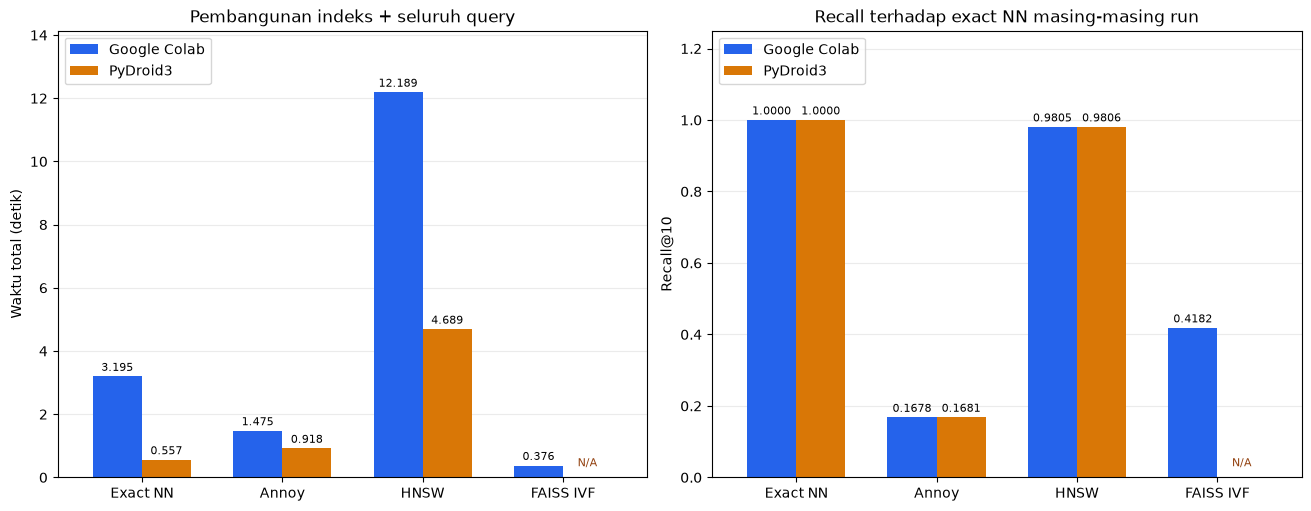

In [5]:
import matplotlib.pyplot as plt

x = np.arange(len(comparison))
width = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, columns, title, ylabel, digits in [
    (axes[0], ['Colab total (s)', 'PyDroid3 total (s)'],
     'Pembangunan indeks + seluruh query', 'Waktu total (detik)', 3),
    (axes[1], ['Recall@10 Colab', 'Recall@10 PyDroid3'],
     'Recall terhadap exact NN masing-masing run', 'Recall@10', 4)
]:
    for offset, column, color, label in [
        (-width/2, columns[0], '#2563eb', 'Google Colab'),
        (width/2, columns[1], '#d97706', 'PyDroid3')
    ]:
        values = comparison[column].to_numpy(dtype=float)
        bars = ax.bar(x+offset, values, width, color=color, label=label)
        for bar, value in zip(bars, values):
            if np.isfinite(value):
                ax.annotate(f'{value:.{digits}f}', (bar.get_x()+bar.get_width()/2, value),
                            xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8)
    ax.set(xticks=x, xticklabels=comparison.index, title=title, ylabel=ylabel)
    ax.set_ylim(0, 1.25 if ax is axes[1] else comparison[columns].max().max()*1.16)
    ax.text(x[-1]+width/2, ax.get_ylim()[1]*0.025, 'N/A', ha='center', fontsize=8, color='#92400e')
    ax.set_xlim(-0.6, len(comparison)-0.4)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend()
plt.show()


## Analisis hasil

1. **PyDroid3 mencatat waktu total lebih singkat pada ketiga model bersama.** Exact NN: 0,557 s dibanding 3,195 s di Colab (rasio 5,74×); Annoy: 0,918 s dibanding 1,475 s (1,61×); HNSW: 4,689 s dibanding 12,189 s (2,60×). Ini adalah hasil satu run pada masing-masing lingkungan, bukan kesimpulan bahwa HP selalu lebih cepat daripada Colab.

2. **Kecepatan perlu dibaca bersama recall.** Annoy mempunyai recall 0,1678 di Colab dan 0,1681 di Android, yaitu sekitar 1,68 dari 10 tetangga exact yang ditemukan per query. Konfigurasi 10 tree pada data sintetis 128 dimensi ini belum menghasilkan kualitas pencarian yang tinggi. HNSW menemukan sekitar 9,81 dari 10 tetangga, dengan recall 0,9805/0,9806, tetapi memiliki waktu total terpanjang pada kedua perangkat.

3. **ANN tidak selalu mengurangi biaya total pada dataset ini.** Di PyDroid3, exact NN justru tercepat untuk seluruh workload (0,557 s), sedangkan Annoy memerlukan 0,918 s dan HNSW 4,689 s. Pengukuran mencakup pembangunan indeks dan seluruh query; hasil ini tidak membuktikan bahwa latensi query HNSW secara terpisah paling lambat. Biaya pembangunan indeks dapat dibagi ke lebih banyak query jika indeks digunakan berulang.

4. **FAISS IVF tetap menjadi hasil Colab saja.** Waktu totalnya 0,376 s, paling singkat di Colab dan sekitar 8,50× lebih singkat daripada exact NN Colab. Namun recall 0,4182 berarti sekitar 4,18 dari 10 tetangga exact ditemukan, sehingga hasilnya belum setara dengan pencarian exact atau HNSW. Tidak ada waktu/recall FAISS Android yang diisi atau diperkirakan.

5. **Lingkungan dan pembulatan membatasi interpretasi antar perangkat.** Colab menggunakan x86_64, NumPy 2.1.3, dan scikit-learn 1.6.1; Android menggunakan aarch64, NumPy 2.4.4, dan scikit-learn 1.8.0. Kedua hash input hasil StandardScaler berhasil direkonstruksi dari perbedaan pembulatan, dengan selisih maksimum sekitar 3,58×10⁻⁷. Data numeriknya sangat dekat tetapi tidak identik byte, sehingga perbandingan ini bersifat deskriptif dan bukan pengukuran pengaruh CPU saja. Model CPU Colab, jumlah thread, suhu/beban perangkat, variasi antar pengulangan, dan versi Python tidak tersedia dalam output.

6. **Spesifikasi HP:** Dimensity 8500 Ultra dan RAM 16 GB sesuai keterangan pengguna, arsitektur aarch64, kernel Android 15 pada output, serta RAM terbaca psutil 11,094 GiB. Nilai RAM spesifikasi dan hasil pembacaan OS ditampilkan terpisah; kapasitas fisik/virtual serta model HP tidak disimpulkan dari angka tersebut.

## Kesimpulan

Untuk workload yang dilaporkan, exact NN menjadi pilihan dengan akurasi tetangga penuh dan waktu paling singkat di PyDroid3. HNSW menawarkan recall mendekati exact dengan biaya total lebih besar. Annoy dan FAISS IVF pada parameter yang diuji mengurangi kualitas hasil tetangga; kecepatan yang tinggi perlu dinilai bersama kebutuhan recall. Di Colab, FAISS IVF paling cepat, sedangkan HNSW paling mendekati exact di antara metode approximate. Perbandingan ketiga model bersama menunjukkan waktu total lebih singkat pada HP dalam run ini, dengan catatan perbedaan lingkungan dan pembulatan di atas.